# RECIPE ILMU KEBUMIAN: PRAKTIK `R-IO-001` DAN RECIPE ORISINAL `R-CHM-001` (AUDIT KONTRAK DATA, LALU CHARGE-BALANCE ERROR ION MAYOR AIR TANAH)

**Nama :** [Cantik S. Banjarnahor] &nbsp;&nbsp; **NIM :** [H061251059]

| Metadata | Praktik buku | Recipe sendiri |
| :--- | :--- | :--- |
| **Recipe ID** | `R-IO-001` (kasus Bab 2.4.1) | `R-CHM-001` |
| **Prompt ID** | `P-IO-001` | `P-CHM-001` |
| **Equation ID** | tidak ada (tanpa persamaan) | `E-CHM-001` |
| **Kelompok kerja** | `io` | `chemistry` |
| **Tingkat workflow** | Atomic prompt, satu skrip read-only | Parameterized + Conditional + Pipeline: `P1 (audit) -> P2 (hitung) -> V (verifikasi independen)` |
| **Jenis klaim** | QA/QC struktur CSV | Verifikasi komputasi dan QA/QC kontrak data. **Bukan** interpretasi hidrogeokimia |
| **Referensi** | *AI Cookbook untuk Earth Sciences*, Bab 2 (2.1 sampai 2.6) | sama |

> **Catatan keterbukaan data.** Semua data pada notebook ini adalah **fixture sintetis** yang saya rancang untuk menguji perilaku kode (kasus normal, kasus gagal, kasus data cacat). Data ini **bukan** hasil pengukuran lapangan dan tidak boleh dibaca sebagai kualitas air tanah suatu lokasi.

---

## Bagian 0. Analisis Bab 2.4 (Recipe sebagai Unit Praktik)

### 0.1 Inti gagasan bab

| Konsep | Isi menurut Bab 2.4 | Implikasi untuk pekerjaan saya |
| :--- | :--- | :--- |
| **Prompt vs recipe** | Prompt hanya instruction. Recipe memuat tujuan ilmiah, input, asumsi, procedure, artifact, dan pemeriksaan. | Prompt saja tidak cukup dikumpulkan; harus ada kode, konfigurasi, output, dan bukti. |
| **Recipe vs algoritme** | Algoritme mendefinisikan langkah komputasi. Recipe mendefinisikan *workflow di sekitar* algoritme (data, config, command, output, interpretasi). | Rumus CBE adalah algoritmenya; audit, kontrak, run record, dan verifikasi adalah recipe-nya. |
| **Alur minimum** | Problem → Minimal Theory → Prompt → Code → Result → Optional Check | Dipakai sebagai urutan bagian di kedua recipe. |
| **Satu recipe = satu outcome** | Audit CSV berbeda dari menghitung indeks kekeringan. | Audit kontrak dan perhitungan CBE saya pisahkan sebagai tahap `P1` dan `P2`, bukan dicampur. |
| **"Optional" bukan boleh dilewati** | Yang berubah adalah tingkat check, bukan tanggung jawab menyatakan batas bukti. | Check dibuat 13 butir, dan dibuktikan *bisa gagal* lewat kontrol negatif. |
| **Label status** | `Executed`, `Offline replay executed`, `Partial`, `Not yet executed`; draft atau expected output bukan bukti run. | Semua klaim "executed" di sini dikaitkan ke run record dan hash. |
| **Identifier dan companion file** | ID stabil (`P-`, `R-`, `E-`, `TN-`, `CS-`); skema `artifacts/`, `code/`, `data/`, `results/`. | Skema direktori dipakai apa adanya; karena tugas diminta satu file, spesifikasi companion ada di notebook ini. |

### 0.2 Tujuh tahap pembuatan recipe (2.4.1) dan cara saya menerapkannya

1. Rumuskan problem dan batas keputusan → bagian "Problem" tiap recipe (satu outcome utama, hal yang *tidak* dikerjakan dinyatakan).
2. Minimal theory dan asumsi → hanya yang menentukan implementasi (konversi unit, rumus CBE, tanda muatan).
3. Input dan constraint contract → path, kolom, unit yang diterima, aturan nilai hilang, larangan menimpa output.
4. Prompt dan mekanisme terkecil → prompt `⟨R,T,C,I,K,O,Q,V⟩`; hanya Python lokal, tanpa plugin, MCP, atau jaringan.
5. Implementasi sebagai artifact → konfigurasi dipisah dari kode; kode memegang perilaku yang tidak bisa dipastikan dari prosa.
6. Output dan check ditetapkan **sebelum** run → file *expected output* dan toleransi ditulis sebelum eksekusi.
7. Jalankan, catat status, revisi dengan evidence → run record berisi command, hash, versi, check, dan exit code.

### 0.3 Pengamatan kritis terhadap bab

* **Fixture `R-IO-001` tidak disertakan di PDF.** Buku hanya menyebut hasilnya (5 baris, 4 kolom, satu temperatur hilang, satu timestamp ganda). Fixture pada Bagian A **saya rekonstruksi dari deskripsi itu**, jadi nilainya bukan nilai asli buku. Status yang jujur adalah *dijalankan pada fixture rekonstruksi*, bukan *mereproduksi run record buku*.
* **Kontrak input `R-IO-001` tidak menyebut satuan.** Skrip saya sengaja melaporkan "satuan tidak dinyatakan" alih-alih menebak dari nama kolom, sesuai larangan menebak unit pada Bab 2.1.2.
* **Run record buku bertanggal 10 September 2026 dan menyatakan "tidak menjalankan ulang recipe".** Artinya hasil buku adalah *dokumentasi*, dan baru menjadi bukti bagi saya setelah saya menjalankannya sendiri (Bagian A.6).
* **Ketegangan desain:** bab meminta check "proporsional dengan risiko", tetapi tidak memberi cara menilai check itu sendiri. Jawaban saya pada Bagian B adalah *kontrol negatif*: check dianggap bermakna hanya bila terbukti bisa gagal.

---

# BAGIAN A. PRAKTIK RECIPE BUKU: `R-IO-001` (Audit Station CSV Sebelum Analisis Iklim)

## A.1 Problem dan batas keputusan

* **Pertanyaan.** Apakah satu tabel stasiun layak menjadi input analisis berikutnya (agregasi harian atau bulanan)?
* **Outcome tunggal.** Report QA/QC: skema, rentang waktu, missing value, timestamp ganda, ringkasan numerik.
* **Bukan outcome recipe ini:** indeks kekeringan, prediksi hujan, imputasi, atau penghapusan record.

## A.2 Minimal theory

Timestamp ganda, nilai hilang, dan tipe kolom yang salah mengubah hasil agregasi, misalnya total hujan harian terhitung dua kali bila satu timestamp muncul dua kali. Karena itu audit dilakukan **sebelum** agregasi, dan bersifat non-destruktif.

## A.3 Input dan constraint

* Input: `data/samples/station-example.csv`, kolom waktu `time` (ISO 8601, UTC).
* Constraint: file input tidak diubah (dibuktikan SHA-256 sebelum dan sesudah); tidak ada imputasi; tidak ada penghapusan record; tanpa jaringan; hanya standard library.

## A.4 Prompt `P-IO-001`

```text
[R] Scientific Python developer untuk QA/QC data observasi.
[T] Buat loader read-only yang mengaudit satu CSV stasiun: skema, rentang waktu, missing value per kolom,
    duplicate timestamp (beserta nomor baris), dan ringkasan numerik.
[C] Audit awal sebelum agregasi harian/bulanan. Hasil hanya untuk menemukan masalah data, bukan untuk analisis iklim.
[I] data/samples/station-example.csv; kolom waktu "time"; satuan TIDAK dinyatakan (laporkan, jangan menebak).
[K] Jangan mengubah/menghapus/mengimputasi record. Hanya standard library. Tanpa jaringan.
[O] results/io/station-summary.md dan results/run-records/r-io-001.json (command, hash, check, status).
[Q] Input tidak kosong; semua baris sepanjang header; SHA-256 input sebelum = sesudah; report tidak kosong.
[V] Jalankan sekali, periksa exit code, dan baca report. Label status mengikuti bukti.
```

## A.5 Implementasi

Fixture direkonstruksi dari deskripsi buku (lihat 0.3), lalu skrip ditulis ke disk.

In [1]:
import os
for d in ["data/samples", "code/recipes/io", "code/recipes/chemistry", "configurations",
          "artifacts/expected-outputs", "results", "figures"]:
    os.makedirs(d, exist_ok=True)
print("direktori siap:", sorted(os.listdir(".")))

direktori siap: ['artifacts', 'code', 'configurations', 'data', 'figures', 'results']


In [2]:
%%writefile data/samples/station-example.csv
time,station_id,temperature_c,rainfall_mm
2026-09-01T00:00:00Z,ST01,27.4,0.0
2026-09-02T00:00:00Z,ST01,27.9,3.2
2026-09-02T00:00:00Z,ST01,28.1,3.2
2026-09-03T00:00:00Z,ST01,,12.5
2026-09-04T00:00:00Z,ST01,26.8,0.4

Writing data/samples/station-example.csv


In [3]:
%%writefile code/recipes/io/r-io-001.py
"""
Recipe ID : R-IO-001      Prompt ID : P-IO-001
Audit QA/QC read-only untuk satu CSV stasiun (Bab 2.4.1, kasus Ilmu Kebumian).
Tidak mengubah, menghapus, atau mengimputasi record sumber.

Pemakaian:
    python3 code/recipes/io/r-io-001.py --input data/samples/station-example.csv \
        --time-column time --report results/io/station-summary.md \
        --record results/run-records/r-io-001.json
Exit code: 0 = selesai dan semua check lulus, 1 = ada check gagal, 2 = kontrak input tidak terpenuhi.
"""
import argparse, collections, csv, datetime, hashlib, json, os, platform, sys


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        h.update(f.read())
    return h.hexdigest()


def to_float(text):
    try:
        return float(text)
    except ValueError:
        return None


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--input", required=True)
    ap.add_argument("--time-column", required=True)
    ap.add_argument("--report", required=True)
    ap.add_argument("--record", required=True)
    a = ap.parse_args()

    sha_before = sha256(a.input)
    with open(a.input, newline="", encoding="utf-8") as f:
        raw = list(csv.reader(f))
    header, body = raw[0], raw[1:]
    if a.time_column not in header or not body:
        print(f"[STOP] kolom waktu '{a.time_column}' tidak ada atau CSV kosong")
        return 2
    rows = [dict(zip(header, r)) for r in body]
    ragged = [i + 2 for i, r in enumerate(body) if len(r) != len(header)]  # nomor baris file

    times = [r[a.time_column] for r in rows]
    parsed = [datetime.datetime.fromisoformat(t.replace("Z", "+00:00")) for t in times if t]
    dup = {t: n for t, n in collections.Counter(times).items() if n > 1}
    dup_rows = [i + 2 for i, t in enumerate(times) if t in dup]
    missing = {c: [i + 2 for i, r in enumerate(rows) if r[c].strip() == ""] for c in header}

    numeric = {}
    for c in header:
        vals = [to_float(r[c]) for r in rows if r[c].strip() != ""]
        if vals and all(v is not None for v in vals) and c != a.time_column:
            numeric[c] = dict(n=len(vals), min=min(vals), max=max(vals), mean=sum(vals) / len(vals))

    lines = ["# Ringkasan audit station CSV (R-IO-001)", "",
             f"- Input: `{a.input}` (SHA-256 `{sha_before[:12]}...`, tidak diubah)",
             f"- Dimensi: {len(rows)} baris x {len(header)} kolom ({', '.join(header)})",
             f"- Rentang waktu ({a.time_column}): {min(parsed).isoformat()} s.d. {max(parsed).isoformat()}",
             f"- Duplicate timestamp: {len(dup)} nilai ganda, pada baris file {dup_rows}", "",
             "## Missing value per kolom (nomor baris file, header = baris 1)", ""]
    for c, rr in missing.items():
        lines.append(f"- {c}: {len(rr)} {rr if rr else ''}".rstrip())
    lines += ["", "## Ringkasan numerik (tanpa imputasi; blank diabaikan)", "",
              "| kolom | n | min | mean | max |", "| :-- | --: | --: | --: | --: |"]
    for c, s in numeric.items():
        lines.append(f"| {c} | {s['n']} | {s['min']:g} | {s['mean']:.3f} | {s['max']:g} |")
    lines += ["", "Satuan tidak dinyatakan dalam kontrak input; nama kolom membawa sufiks `_c` dan `_mm` "
              "sebagai petunjuk, bukan bukti satuan."]

    os.makedirs(os.path.dirname(a.report), exist_ok=True)
    with open(a.report, "w", encoding="utf-8") as f:
        f.write("\n".join(lines) + "\n")

    checks = [
        dict(name="input tidak kosong", value=len(rows), passed=len(rows) > 0),
        dict(name="struktur CSV: semua baris sepanjang header", value=ragged, passed=not ragged),
        dict(name="input tidak berubah (SHA-256 sebelum = sesudah)", value=sha256(a.input) == sha_before,
             passed=sha256(a.input) == sha_before),
        dict(name="report tidak kosong", value=os.path.getsize(a.report), passed=os.path.getsize(a.report) > 0),
    ]
    ok = all(c["passed"] for c in checks)
    record = dict(
        recipe_id="R-IO-001", prompt_id="P-IO-001",
        command=" ".join([os.path.basename(sys.executable)] + sys.argv),
        timestamp_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
        environment=dict(python=platform.python_version(), platform=platform.platform()),
        input=dict(path=a.input, sha256=sha_before, rows=len(rows), columns=len(header)),
        findings=dict(missing_by_column={c: len(r) for c, r in missing.items()},
                      duplicate_timestamps=len(dup), duplicate_rows=dup_rows),
        checks=checks, checks_all_passed=ok, exit_code=0 if ok else 1,
        status="Executed - all checks passed" if ok else "Executed - one or more checks FAILED",
        output=dict(path=a.report, sha256=sha256(a.report)),
    )
    os.makedirs(os.path.dirname(a.record), exist_ok=True)
    with open(a.record, "w", encoding="utf-8") as f:
        json.dump(record, f, indent=2, ensure_ascii=False)
    print(f"R-IO-001 -> {record['status']}")
    print(f"  {len(rows)} rows x {len(header)} columns | missing: "
          f"{ {c: len(r) for c, r in missing.items() if r} } | duplicate timestamp: {len(dup)}")
    for c in checks:
        print(f"  [{'PASS' if c['passed'] else 'FAIL'}] {c['name']}: {c['value']}")
    print(f"Report: {a.report}\nRun record: {a.record}")
    return 0 if ok else 1


if __name__ == "__main__":
    sys.exit(main())

Writing code/recipes/io/r-io-001.py


## A.6 Run

> *Catatan keterbukaan eksekusi:* keluaran sel di notebook ini ditangkap dari run nyata perintah yang sama di shell Linux (bukan dari kernel Jupyter). Menjalankan ulang sel di Jupyter memberi keluaran numerik yang sama; yang berbeda hanya `timestamp_utc` dan path lingkungan pada run record.

In [4]:
!python3 code/recipes/io/r-io-001.py --input data/samples/station-example.csv --time-column time --report results/io/station-summary.md --record results/run-records/r-io-001.json; echo "exit code: $?"

R-IO-001 -> Executed - all checks passed
  5 rows x 4 columns | missing: {'temperature_c': 1} | duplicate timestamp: 1
  [PASS] input tidak kosong: 5
  [PASS] struktur CSV: semua baris sepanjang header: []
  [PASS] input tidak berubah (SHA-256 sebelum = sesudah): True
  [PASS] report tidak kosong: 809
Report: results/io/station-summary.md
Run record: results/run-records/r-io-001.json
exit code: 0


In [5]:
!cat results/io/station-summary.md

# Ringkasan audit station CSV (R-IO-001)

- Input: `data/samples/station-example.csv` (SHA-256 `b390ccf3aa3e...`, tidak diubah)
- Dimensi: 5 baris x 4 kolom (time, station_id, temperature_c, rainfall_mm)
- Rentang waktu (time): 2026-09-01T00:00:00+00:00 s.d. 2026-09-04T00:00:00+00:00
- Duplicate timestamp: 1 nilai ganda, pada baris file [3, 4]

## Missing value per kolom (nomor baris file, header = baris 1)

- time: 0
- station_id: 0
- temperature_c: 1 [5]
- rainfall_mm: 0

## Ringkasan numerik (tanpa imputasi; blank diabaikan)

| kolom | n | min | mean | max |
| :-- | --: | --: | --: | --: |
| temperature_c | 4 | 26.8 | 27.550 | 28.1 |
| rainfall_mm | 5 | 0 | 3.860 | 12.5 |

Satuan tidak dinyatakan dalam kontrak input; nama kolom membawa sufiks `_c` dan `_mm` sebagai petunjuk, bukan bukti satuan.


## A.7 Result dan interpretasi (observasi, perhitungan, inferensi, batasan dipisah)

* **Observasi.** Fixture berisi 5 baris dan 4 kolom. Kolom `temperature_c` memiliki 1 nilai kosong (baris file 5). Terdapat 1 timestamp ganda, yaitu `2026-09-02T00:00:00Z` pada baris file [3, 4].
* **Perhitungan.** Rata-rata `temperature_c` (4 nilai valid) 27,550; total `rainfall_mm` dari 5 nilai = 19,3 (rata-rata 3,860). Angka ini dihitung **tanpa** mengimputasi baris yang kosong.
* **Inferensi (terbatas).** Bila agregasi harian dijalankan tanpa menangani duplikat, curah hujan 2 September (3,2 mm) berisiko terhitung dua kali. Dua baris duplikat memiliki temperatur berbeda (27,9 dan 28,1), sehingga **tidak dapat ditentukan secara otomatis** mana yang benar.
* **Batasan.** Keputusan duplikat dan nilai kosong **belum dibuat**; itu keputusan manusia pada recipe berikutnya. Satuan tidak diverifikasi karena kontrak input tidak menyatakannya. Fixture adalah rekonstruksi, bukan data asli buku.

**Status bukti A:** `Executed - all checks passed`, exit code `0`, 2026-10-21T03:51:04+00:00 UTC. Hash input `b390ccf3aa3e…`, hash report `fcd68772494b…`. Empat check pada run record seluruhnya lulus.

---

# BAGIAN B. RECIPE SENDIRI: `R-CHM-001` (Charge-Balance Error Ion Mayor Air Tanah)

## B.1 Problem dan batas keputusan

* **Pertanyaan ilmiah.** Dari tabel analisis ion mayor air tanah, sampel mana yang secara muatan cukup setimbang untuk dipakai pada analisis hidrokimia berikutnya, mana yang perlu ditinjau ulang, dan mana yang **tidak dapat dihitung** karena kontrak datanya tidak terpenuhi?
* **Pengguna hasil.** Peneliti atau mahasiswa yang menyaring data laboratorium sebelum membuat diagram Piper atau menafsirkan fasies air.
* **Keputusan yang didukung.** Penyaringan awal (QA/QC): lanjut, tinjau ulang, atau tahan sampel. Bukan keputusan tentang sumber kontaminasi atau intrusi air laut.
* **Satu outcome utama.** Tabel `balance.csv` (satu baris per baris input) + figure + run record.
* **Sengaja tidak dikerjakan** (Bab 2.4.1 langkah 1): spesiasi, ionic strength, rasio ion untuk indikasi salinisasi, interpretasi sumber. Itu recipe terpisah dengan risiko ilmiah berbeda.
* **Mengapa dibuat pipeline `P1 -> P2` dan bukan satu skrip tunggal.** Kegagalan *kontrak data* (unit kosong, ion hilang) berbeda sifatnya dari kegagalan *perhitungan*. Dengan artifact `audit.csv` di antara keduanya, setiap kegagalan bisa dilacak ke tahap penyebabnya.

## B.2 Minimal theory dan asumsi (`E-CHM-001`)

Konversi konsentrasi massa ke ekuivalen (konsentrasi `c` dalam mg/L, massa molekul `M` dalam g/mol, muatan `z`):

$$ q_i\;[\mathrm{meq/L}] = \frac{c_i\,|z_i|}{M_i} $$

Charge-balance error (elektronetralitas larutan):

$$ \mathrm{CBE}\,[\%] = \frac{\sum q_{+} - \sum q_{-}}{\sum q_{+} + \sum q_{-}} \times 100 $$

| Ion | Tipe | Muatan *z* | *M* di konfigurasi (g/mol) |
| :-- | :-: | :-: | :-: |
| Ca²⁺ | kation | +2 | 40,078 |
| Mg²⁺ | kation | +2 | 24,305 |
| Na⁺ | kation | +1 | 22,990 |
| K⁺ | kation | +1 | 39,098 |
| HCO₃⁻ | anion | −1 | 61,017 |
| Cl⁻ | anion | −1 | 35,45 |
| SO₄²⁻ | anion | −2 | 96,06 |
| NO₃⁻ (opsional) | anion | −1 | 62,004 |

**Klasifikasi** (ambang ditetapkan di konfigurasi sebelum run, dapat diganti per proyek): $|\mathrm{CBE}|\le 5\%$ → `lulus`; $5<|\mathrm{CBE}|\le 10\%$ → `peringatan`; $>10\%$ → `gagal`. Angka 5% dan 10% adalah **pilihan penyaringan yang umum dipakai, bukan hukum alam**.

**Asumsi dan batas:**

1. HCO₃⁻ dibaca sebagai alkalinitas bikarbonat; karbonat, ion organik, dan spesies lain tidak dimodelkan.
2. Ion opsional yang **tidak diukur** (sel kosong) **dikeluarkan dari jumlah**, bukan diisi nol, karena nol berarti "terukur sebesar nol".
3. Nilai tersensor (mis. `<0.1`) dan nilai negatif **tidak disubstitusi**; sampelnya diberi status `tidak_dapat_dihitung`.
4. Pada total ion yang sangat kecil (air hujan atau air tawar encer), selisih absolut kecil dapat menghasilkan CBE besar; hasilnya harus dibaca bersama $\sum q$.
5. CBE kecil adalah **syarat perlu, bukan syarat cukup**: kesalahan yang saling meniadakan tidak terdeteksi.

## B.3 Input dan constraint contract

### Input
* `data/samples/groundwater-major-ions.csv` (15 baris, fixture sintetis). Kolom: `sample_id`, `unit`, `Ca`, `Mg`, `Na`, `K`, `HCO3`, `Cl`, `SO4`, `NO3`. Tanpa koordinat, alamat, atau nama pemilik sumur.
* `configurations/r-chm-001.json`: satu-satunya sumber parameter (kolom, ion, muatan, massa molekul, ambang, toleransi).
* **Input yang dilarang:** parameter yang ditulis ulang di dalam kode utama; data dari run lain; jaringan.

### Desain fixture (ditulis agar tiap cabang kode teruji)

| Baris | `sample_id` | Skenario yang diuji | Perilaku yang diharapkan |
| :-: | :-- | :-- | :-- |
| 1–4 | GW-01…GW-04 | air tawar normal sampai payau, CBE kecil | `lulus` (GW-04 sengaja dekat batas 5%) |
| 5 | GW-05 | CBE moderat | `peringatan` |
| 6 | GW-06 | kation berlebih | `gagal` |
| 7 | GW-07 | K kosong (ion wajib) | `tidak_dapat_dihitung` |
| 8 | GW-08 | `unit` kosong | `tidak_dapat_dihitung` |
| 9 | GW-09 | `unit` = `ppm` (tidak diterima kontrak) | `tidak_dapat_dihitung` |
| 10 | GW-10 | `unit` = `meq/L` (tanpa konversi) | dihitung langsung |
| 11 | GW-02 | **ID ganda** (analisis ulang?) | kedua baris dipertahankan dan diberi flag |
| 12 | GW-12 | HCO₃ negatif | `tidak_dapat_dihitung` |
| 13 | GW-13 | K = `<0.1` (tersensor) | `tidak_dapat_dihitung` |
| 14 | GW-14 | total ion sangat kecil | dihitung (uji kepekaan CBE pada total kecil) |
| 15 | GW-15 | NO₃ kosong (opsional) | dihitung, NO₃ dikeluarkan dari jumlah |

### Constraints (dapat diuji lewat check, exit code, atau `diff`)
1. Tidak ada imputasi, substitusi nilai tersensor, atau penghapusan baris. Jumlah baris output = jumlah baris input.
2. Unit hanya `mg/L` atau `meq/L` (pencocokan persis; `mg/l` atau `ppm` ditolak, tidak ditebak).
3. Kolom yang disyaratkan kontrak tidak ada → **berhenti** dengan exit code 2.
4. Input harus identik antara tahap audit dan tahap hitung (SHA-256); bila berubah → berhenti (exit 2).
5. Output tidak pernah menimpa: bila direktori run sudah ada → **tolak** (exit 3); lanjut hanya dengan `run_name` baru (ini bentuk *human gate* `[H]` pada Tabel 2.1).
6. Pustaka: standard library dan `matplotlib` saja; tanpa jaringan.
7. Ekspektasi dan toleransi ditulis **sebelum** run dan tidak diubah agar hasil lulus.

---

## B.4 Reusable Prompt Specification (`P-CHM-001`)

Disusun mengikuti $P=\langle R,T,C,I,K,O,Q,V\rangle$ (Bab 2.1). Notasi alur (Bab 2.3): `P1 -> P2 -> V`, dengan percabangan terukur per baris `unit_valid ? hitung : flag`.

```text
[Role (R)]
Scientific Python developer dan reviewer QA/QC hidrokimia. Peran hanya menentukan prioritas (unit, tanda muatan,
perlakuan nilai hilang), BUKAN bukti kebenaran hasil.

[Task (T)]
P1 - Audit: periksa data/samples/groundwater-major-ions.csv terhadap kontrak (kolom, unit, ion wajib, nilai valid,
     ID ganda) dan tulis audit.csv + audit.json tanpa mengubah input.
P2 - Hitung: gunakan HANYA audit.csv dan CSV input untuk mengonversi mg/L ke meq/L, menghitung jumlah kation,
     jumlah anion, CBE (%), dan kelas per baris. Baris yang tidak memenuhi kontrak diberi status
     tidak_dapat_dihitung dengan alasan, tanpa angka CBE.
V  - Verifikasi: hitung ulang independen dan jalankan check.

[Context (C)]
Penyaringan awal data ion mayor sebelum diagram Piper atau interpretasi fasies. Hanya QA/QC; jangan menyimpulkan
sumber kontaminasi atau salinisasi.

[Input (I)]
configurations/r-chm-001.json dan data/samples/groundwater-major-ions.csv. Unit per baris: mg/L atau meq/L.
HCO3 = bikarbonat. Fixture sintetis. Tanpa jaringan.

[Constraints (K)]
1. Jangan mengubah input, mengimputasi, mengganti nilai tersensor, atau menghapus baris.
2. Ion opsional kosong dikeluarkan dari jumlah (bukan nol). Ion wajib kosong -> tidak_dapat_dihitung.
3. Kolom kontrak hilang atau input berubah antar tahap -> berhenti (exit 2). Output sudah ada -> tolak (exit 3).
4. Jangan menyesuaikan ambang atau toleransi agar check lulus.

[Output (O)]
results/chemistry/r-chm-001/<run>/{audit.csv, audit.json, balance.csv, summary.json, stage-log.json}
figures/chemistry/r-chm-001_<run>.png
results/run-records/r-chm-001-<run>.json  (command, versi, SHA-256, check, status, exit code)

[Quality Criteria (Q)]
Jumlah baris terjaga; urutan ID terjaga; jumlah per status = expected-output; CBE program vs hitung ulang independen
<= 0,02 poin persen; tabel massa molekul dan muatan cocok dengan sumber independen (rel <= 1e-3);
hitungan tangan 1 mmol/L benar; semua CBE finite.

[Verification (V)]
Hitung ulang CBE dari baris mentah dengan massa atom dan muatan yang ditulis terpisah; uji sifat (invarian skala,
rumus analitik skala anion); kontrol negatif (muatan Mg sengaja salah) harus membuat check gagal; rerun di
direktori bersih dan bandingkan SHA-256. Pisahkan observasi, perhitungan, inferensi, dan batasan.
```

## B.5 Implementasi

Ekspektasi ditulis lebih dulu (Bab 2.6.1: *expected output* bukan hasil aktual), lalu data, konfigurasi, dan kode.

In [6]:
%%writefile artifacts/expected-outputs/r-chm-001.json
{
  "recipe_id": "R-CHM-001",
  "note": "Ekspektasi ditulis SEBELUM run dari desain fixture; bukan hasil aktual.",
  "n_rows": 15,
  "n_unique_ids": 14,
  "duplicate_ids": [
    "GW-02"
  ],
  "status_counts": {
    "lulus": 8,
    "peringatan": 1,
    "gagal": 1,
    "tidak_dapat_dihitung": 5
  },
  "not_computable_ids": [
    "GW-07",
    "GW-08",
    "GW-09",
    "GW-12",
    "GW-13"
  ]
}

Writing artifacts/expected-outputs/r-chm-001.json


In [7]:
%%writefile data/samples/groundwater-major-ions.csv
sample_id,unit,Ca,Mg,Na,K,HCO3,Cl,SO4,NO3
GW-01,mg/L,60.12,18.23,57.47,3.91,256.27,81.53,28.82,3.10
GW-02,mg/L,84.16,34.03,137.94,7.82,305.09,230.43,67.24,12.40
GW-03,mg/L,110.21,54.69,574.75,31.28,366.10,957.15,144.09,6.20
GW-04,mg/L,40.08,12.15,41.38,3.91,170.85,42.54,19.21,6.20
GW-05,mg/L,70.14,24.30,91.96,7.82,244.07,131.17,38.42,6.20
GW-06,mg/L,120.23,36.46,229.90,19.55,305.09,283.60,72.05,18.60
GW-07,mg/L,60.12,18.23,57.47,,256.27,81.53,28.82,3.10
GW-08,,60.12,18.23,57.47,3.91,256.27,81.53,28.82,3.10
GW-09,ppm,60.12,18.23,57.47,3.91,256.27,81.53,28.82,3.10
GW-10,meq/L,2.50,1.20,3.00,0.10,3.50,2.60,0.70,0.00
GW-02,mg/L,86.17,32.81,140.24,7.82,311.19,226.88,72.05,12.40
GW-12,mg/L,60.12,18.23,57.47,3.91,-256.27,81.53,28.82,3.10
GW-13,mg/L,60.12,18.23,57.47,<0.1,256.27,81.53,28.82,3.10
GW-14,mg/L,3.01,0.61,4.60,0.78,6.10,6.38,3.84,1.86
GW-15,mg/L,64.12,21.87,68.97,5.86,244.07,99.26,57.64,

Writing data/samples/groundwater-major-ions.csv


In [8]:
%%writefile configurations/r-chm-001.json
{
  "run_name": "baseline",
  "run_kind": "baseline",
  "description": "Audit kontrak lalu charge-balance error untuk fixture sintetis 15 baris.",
  "input_csv": "data/samples/groundwater-major-ions.csv",
  "id_column": "sample_id",
  "unit_column": "unit",
  "accepted_units": [
    "mg/L",
    "meq/L"
  ],
  "ions": {
    "Ca": {
      "column": "Ca",
      "type": "cation",
      "charge": 2,
      "mw": 40.078
    },
    "Mg": {
      "column": "Mg",
      "type": "cation",
      "charge": 2,
      "mw": 24.305
    },
    "Na": {
      "column": "Na",
      "type": "cation",
      "charge": 1,
      "mw": 22.99
    },
    "K": {
      "column": "K",
      "type": "cation",
      "charge": 1,
      "mw": 39.098
    },
    "HCO3": {
      "column": "HCO3",
      "type": "anion",
      "charge": -1,
      "mw": 61.017
    },
    "Cl": {
      "column": "Cl",
      "type": "anion",
      "charge": -1,
      "mw": 35.45
    },
    "SO4": {
      "column": "SO4",
      "type": "anion",
      "charge": -2,
      "mw": 96.06
    },
    "NO3": {
      "column": "NO3",
      "type": "anion",
      "charge": -1,
      "mw": 62.004
    }
  },
  "required_ions": [
    "Ca",
    "Mg",
    "Na",
    "K",
    "HCO3",
    "Cl",
    "SO4"
  ],
  "optional_ions": [
    "NO3"
  ],
  "thresholds": {
    "pass_abs_pct": 5.0,
    "warn_abs_pct": 10.0
  },
  "sensitivity": {
    "hco3_perturb_pct": 2.0,
    "near_boundary_pct_pt": 1.0
  },
  "tolerances": {
    "independent_cbe_abs_pct_pt": 0.02,
    "mw_rel": 0.001,
    "identity_abs": 1e-09,
    "hand_calc_abs": 1e-06
  },
  "expected_outputs": "artifacts/expected-outputs/r-chm-001.json"
}

Writing configurations/r-chm-001.json


In [9]:
%%writefile code/recipes/chemistry/r-chm-001.py
"""
Recipe ID : R-CHM-001     Prompt ID : P-CHM-001     Equation : E-CHM-001
Charge-balance error (CBE) ion mayor air tanah: P1 audit kontrak -> P2 hitung -> V verifikasi independen.

Pemakaian (tiga tahap, masing-masing meninggalkan artifact):
    python3 code/recipes/chemistry/r-chm-001.py --config configurations/r-chm-001.json --stage audit
    python3 code/recipes/chemistry/r-chm-001.py --config configurations/r-chm-001.json --stage compute
    python3 code/recipes/chemistry/r-chm-001.py --config configurations/r-chm-001.json --stage verify

Exit code: 0 = tahap selesai (verify: semua check lulus; kontrol negatif: check gagal seperti diharapkan)
           1 = verify: ada check gagal (kontrol negatif: tidak ada yang gagal, tidak diharapkan)
           2 = berhenti oleh kontrak/guard (tidak ada output yang dipromosikan)
           3 = menolak menimpa output yang sudah ada
Hanya standard library + matplotlib; tanpa jaringan.
"""
import argparse
import csv
import datetime
import hashlib
import json
import math
import os
import platform
import statistics
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

S_OK, S_WARN, S_FAIL, S_NA = "lulus", "peringatan", "gagal", "tidak_dapat_dihitung"


class ContractError(RuntimeError):
    """Kontrak input/konfigurasi tidak terpenuhi -> exit 2."""


class OverwriteError(RuntimeError):
    """Output sudah ada -> exit 3."""


# ----------------------------------------------------------------------------- utilitas umum
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 16), b""):
            h.update(chunk)
    return h.hexdigest()


def now_utc():
    return datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")


def dump_json(path, obj):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)


def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def parse_conc(text):
    """Teks sel -> (nilai | None, jenis). jenis: ok | missing | non_numeric | negative."""
    s = (text or "").strip()
    if s == "":
        return None, "missing"
    try:
        v = float(s)
    except ValueError:
        return None, "non_numeric"          # mis. "<0.1" (censored): tidak disubstitusi
    if not math.isfinite(v):
        return None, "non_numeric"
    if v < 0:
        return None, "negative"
    return v, "ok"


def get_paths(cfg, root):
    neg = cfg.get("run_kind") == "negative_control"
    name = cfg["run_name"]
    base = os.path.join(root, "results", "failed-runs" if neg else "", "chemistry", "r-chm-001", name)
    return dict(
        out=os.path.normpath(base),
        record=os.path.join(root, "results", "run-records", f"r-chm-001-{name}.json"),
        fig=os.path.join(root, "figures", "chemistry", f"r-chm-001_{name}.png"),
    )


def log_stage(out, stage, exit_code, note=""):
    p = os.path.join(out, "stage-log.json")
    log = load_json(p) if os.path.exists(p) else []
    log.append(dict(stage=stage, timestamp_utc=now_utc(), exit_code=exit_code, note=note))
    dump_json(p, log)


def read_input(cfg, root):
    path = os.path.join(root, cfg["input_csv"])
    with open(path, newline="", encoding="utf-8") as f:
        rd = csv.DictReader(f)
        header = rd.fieldnames or []
        rows = list(rd)
    return path, header, rows


def check_config(cfg):
    for ion in cfg["required_ions"] + cfg["optional_ions"]:
        if ion not in cfg["ions"]:
            raise ContractError(f"ion '{ion}' ada di daftar wajib/opsional tetapi tidak di tabel ions")
    for ion, d in cfg["ions"].items():
        if (d["type"] == "cation") != (d["charge"] > 0) or d["charge"] == 0:
            raise ContractError(f"{ion}: tanda muatan {d['charge']} tidak cocok dengan tipe {d['type']}")
        if d["mw"] <= 0:
            raise ContractError(f"{ion}: massa molekul harus positif")


# ----------------------------------------------------------------------------- inti perhitungan (E-CHM-001)
def to_meq(ion, value, unit, cfg):
    """meq/L = mg/L * |z| / MW ; jika unit sudah meq/L nilai dipakai apa adanya."""
    if unit == "meq/L":
        return value
    d = cfg["ions"][ion]
    return value * abs(d["charge"]) / d["mw"]


def balance(values, unit, cfg, scale=None):
    """values: {ion: nilai | None}. None = opsional tidak diukur -> dikeluarkan dari jumlah (bukan nol).
    Return (sum_kation, sum_anion, CBE%) ; CBE None bila jumlah total nol."""
    cat = an = 0.0
    for ion, v in values.items():
        if v is None:
            continue
        m = to_meq(ion, v * (scale or {}).get(ion, 1.0), unit, cfg)
        if cfg["ions"][ion]["type"] == "cation":
            cat += m
        else:
            an += m
    tot = cat + an
    return cat, an, (None if tot == 0 else (cat - an) / tot * 100.0)


def classify(cbe, cfg):
    a, t = abs(cbe), cfg["thresholds"]
    return S_OK if a <= t["pass_abs_pct"] else S_WARN if a <= t["warn_abs_pct"] else S_FAIL


def row_values(cfg, row):
    vals = {}
    for ion in cfg["required_ions"] + cfg["optional_ions"]:
        v, kind = parse_conc(row[cfg["ions"][ion]["column"]])
        vals[ion] = v if kind == "ok" else None
    return vals


# ----------------------------------------------------------------------------- P1: audit
def audit_rows(cfg, rows):
    ions = cfg["ions"]
    ids = [(r[cfg["id_column"]] or "").strip() for r in rows]
    count = {}
    for i in ids:
        count[i] = count.get(i, 0) + 1
    out = []
    for n, (row, sid) in enumerate(zip(rows, ids), start=1):
        unit = (row[cfg["unit_column"]] or "").strip()
        u_status = "ok" if unit in cfg["accepted_units"] else ("blank" if unit == "" else "not_accepted")
        reasons, opt_missing = [], []
        if sid == "":
            reasons.append("id_blank")
        if u_status != "ok":
            reasons.append(f"unit_{u_status}")
        for ion in cfg["required_ions"]:
            _, kind = parse_conc(row[ions[ion]["column"]])
            if kind != "ok":
                reasons.append(f"{ion}:{kind}")
        for ion in cfg["optional_ions"]:
            _, kind = parse_conc(row[ions[ion]["column"]])
            if kind == "missing":
                opt_missing.append(ion)               # boleh: dikeluarkan dari jumlah, bukan diisi nol
            elif kind != "ok":
                reasons.append(f"{ion}:{kind}")
        out.append(dict(row_number=n, sample_id=sid, unit_raw=unit, unit_status=u_status,
                        optional_missing=";".join(opt_missing), duplicate_id=count[sid] > 1,
                        computable=not reasons, reason=";".join(reasons)))
    return out


def stage_audit(cfg, root, paths):
    check_config(cfg)
    in_path, header, rows = read_input(cfg, root)
    need = [cfg["id_column"], cfg["unit_column"]] + [cfg["ions"][i]["column"]
                                                       for i in cfg["required_ions"] + cfg["optional_ions"]]
    absent = [c for c in need if c not in header]
    if absent:
        raise ContractError(f"kolom yang disyaratkan kontrak tidak ada di CSV: {absent}")
    if not rows:
        raise ContractError("CSV tidak memiliki baris data")
    if os.path.exists(paths["out"]):
        raise OverwriteError(f"{os.path.relpath(paths['out'], root)} sudah ada; gunakan run_name baru")
    os.makedirs(paths["out"])

    audit = audit_rows(cfg, rows)
    cols = ["row_number", "sample_id", "unit_raw", "unit_status", "optional_missing",
            "duplicate_id", "computable", "reason"]
    with open(os.path.join(paths["out"], "audit.csv"), "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=cols)
        w.writeheader()
        w.writerows(audit)
    meta = dict(input_csv=cfg["input_csv"], input_sha256=sha256(in_path), n_rows=len(rows), header=header,
                n_computable=sum(a["computable"] for a in audit),
                n_not_computable=sum(not a["computable"] for a in audit),
                n_rows_with_duplicate_id=sum(a["duplicate_id"] for a in audit))
    dump_json(os.path.join(paths["out"], "audit.json"), meta)
    log_stage(paths["out"], "audit", 0)
    print(f"[audit:{cfg['run_name']}] {meta['n_rows']} baris | dapat dihitung {meta['n_computable']} | "
          f"tidak dapat dihitung {meta['n_not_computable']} | baris ber-ID ganda {meta['n_rows_with_duplicate_id']}")
    for a in audit:
        if not a["computable"] or a["duplicate_id"] or a["optional_missing"]:
            flags = a["reason"] or ("ID ganda" if a["duplicate_id"] else f"opsional kosong: {a['optional_missing']}")
            print(f"  baris {a['row_number']:>2} {a['sample_id']:<6} -> {flags}")
    return 0


# ----------------------------------------------------------------------------- P2: compute
def stage_compute(cfg, root, paths):
    check_config(cfg)
    out = paths["out"]
    for need in ("audit.csv", "audit.json"):
        if not os.path.exists(os.path.join(out, need)):
            raise ContractError(f"{need} tidak ada: jalankan --stage audit lebih dulu")
    if os.path.exists(os.path.join(out, "balance.csv")):
        raise OverwriteError("balance.csv sudah ada; gunakan run_name baru")
    meta = load_json(os.path.join(out, "audit.json"))
    in_path, header, rows = read_input(cfg, root)
    if sha256(in_path) != meta["input_sha256"]:
        raise ContractError("input berubah sejak tahap audit (SHA-256 berbeda); hentikan dan tinjau")
    with open(os.path.join(out, "audit.csv"), newline="", encoding="utf-8") as f:
        audit = list(csv.DictReader(f))
    if len(audit) != len(rows) or any(a["sample_id"] != (r[cfg["id_column"]] or "").strip()
                                      for a, r in zip(audit, rows)):
        raise ContractError("audit.csv tidak cocok dengan CSV input (jumlah/urutan baris)")

    pct = cfg["sensitivity"]["hco3_perturb_pct"] / 100.0
    results, sens_changed = [], []
    for a, row in zip(audit, rows):
        res = dict(row_number=int(a["row_number"]), sample_id=a["sample_id"], unit=a["unit_raw"],
                   status=S_NA, cat=None, an=None, cbe=None, optional_excluded=a["optional_missing"],
                   duplicate_id=a["duplicate_id"] == "True", reason=a["reason"])
        if a["computable"] == "True":
            vals = row_values(cfg, row)
            cat, an, cbe = balance(vals, a["unit_raw"], cfg)
            if cbe is None:
                res["reason"] = "jumlah_ion_nol"
            else:
                res.update(status=classify(cbe, cfg), cat=cat, an=an, cbe=cbe)
                for sign in (+1, -1):                        # sensitivitas HCO3 (ketidakpastian analitik alkalinitas)
                    _, _, c2 = balance(vals, a["unit_raw"], cfg, scale={"HCO3": 1 + sign * pct})
                    if classify(c2, cfg) != res["status"] and res["sample_id"] not in sens_changed:
                        sens_changed.append(res["sample_id"])
        results.append(res)

    def f6(x):
        return "" if x is None else f"{x:.6f}"

    cols = ["row_number", "sample_id", "unit", "status", "sum_cations_meq", "sum_anions_meq", "cbe_pct",
            "optional_ions_excluded", "duplicate_id", "reason"]
    with open(os.path.join(out, "balance.csv"), "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(cols)
        for r in results:
            w.writerow([r["row_number"], r["sample_id"], r["unit"], r["status"], f6(r["cat"]), f6(r["an"]),
                        "" if r["cbe"] is None else f"{r['cbe']:.4f}", r["optional_excluded"],
                        r["duplicate_id"], r["reason"]])

    t = cfg["thresholds"]
    nb = cfg["sensitivity"]["near_boundary_pct_pt"]
    near = [f"{r['sample_id']}#{r['row_number']}" for r in results if r["cbe"] is not None
            and min(abs(abs(r["cbe"]) - t["pass_abs_pct"]), abs(abs(r["cbe"]) - t["warn_abs_pct"])) <= nb]
    counts = {s: sum(r["status"] == s for r in results) for s in (S_OK, S_WARN, S_FAIL, S_NA)}
    absc = [abs(r["cbe"]) for r in results if r["cbe"] is not None]
    summary = dict(run_name=cfg["run_name"], run_kind=cfg.get("run_kind"), n_rows=len(results),
                   n_unique_ids=len({r["sample_id"] for r in results}), status_counts=counts,
                   duplicate_ids=sorted({r["sample_id"] for r in results if r["duplicate_id"]}),
                   not_computable={f"{r['sample_id']}#{r['row_number']}": r["reason"]
                                   for r in results if r["status"] == S_NA},
                   abs_cbe_pct=dict(min=min(absc), median=statistics.median(absc), max=max(absc)),
                   thresholds=cfg["thresholds"],
                   sensitivity=dict(hco3_perturb_pct=cfg["sensitivity"]["hco3_perturb_pct"],
                                    ids_changing_status=sens_changed,
                                    near_boundary_pct_pt=cfg["sensitivity"]["near_boundary_pct_pt"],
                                    ids_near_boundary=near))
    dump_json(os.path.join(out, "summary.json"), summary)
    write_figure(results, cfg, paths["fig"])
    log_stage(out, "compute", 0)
    print(f"[compute:{cfg['run_name']}] status: {counts}")
    for r in results:
        cbe = "          -" if r["cbe"] is None else f"{r['cbe']:>+9.2f}%"
        print(f"  baris {r['row_number']:>2} {r['sample_id']:<6} {r['status']:<21} CBE={cbe}"
              + (f"  ({r['reason']})" if r["reason"] else ""))
    print(f"  sensitivitas HCO3 +/-{cfg['sensitivity']['hco3_perturb_pct']:g}% mengubah kelas: "
          f"{sens_changed if sens_changed else 'tidak ada'}")
    print(f"  dekat batas kelas (<= {nb:g} poin persen dari 5%/10%): {near if near else 'tidak ada'}")
    return 0


def write_figure(results, cfg, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    col = {S_OK: "#0072B2", S_WARN: "#E69F00", S_FAIL: "#D55E00"}
    mk = {S_OK: "o", S_WARN: "s", S_FAIL: "^"}
    lab = {S_OK: "lulus (|CBE| <= 5%)", S_WARN: "peringatan (5-10%)", S_FAIL: "gagal (> 10%)"}
    ink, muted = "#1f2328", "#6b7280"
    comp = [r for r in results if r["status"] != S_NA]
    p5, p10 = cfg["thresholds"]["pass_abs_pct"], cfg["thresholds"]["warn_abs_pct"]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.4), dpi=200, gridspec_kw={"width_ratios": [1, 1.1]})
    for ax in (ax1, ax2):
        ax.grid(True, color="#e5e7eb", linewidth=0.6)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
        ax.tick_params(colors=muted, labelsize=8.5)

    lo = min(min(r["cat"], r["an"]) for r in comp) * 0.6
    hi = max(max(r["cat"], r["an"]) for r in comp) * 1.7
    xs = [lo, hi]
    ax1.plot(xs, xs, color=ink, linewidth=1, label="CBE = 0")
    for p, ls in ((p5, "--"), (p10, ":")):
        k_hi, k_lo = (1 - p / 100) / (1 + p / 100), (1 + p / 100) / (1 - p / 100)
        ax1.plot(xs, [x * k_hi for x in xs], color=muted, linestyle=ls, linewidth=1,
                 label=f"CBE = +/-{p:g}%" if k_hi else None)
        ax1.plot(xs, [x * k_lo for x in xs], color=muted, linestyle=ls, linewidth=1)
    for s in (S_OK, S_WARN, S_FAIL):
        pts = [r for r in comp if r["status"] == s]
        if pts:
            ax1.scatter([r["cat"] for r in pts], [r["an"] for r in pts], s=46, marker=mk[s], color=col[s],
                        edgecolor="white", linewidth=0.8, label=lab[s], zorder=3)
    for r in comp:
        ax1.annotate(r["sample_id"], (r["cat"], r["an"]), xytext=(4, -9), textcoords="offset points",
                     fontsize=6.5, color=ink)
    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax1.set_xlim(lo, hi)
    ax1.set_ylim(lo, hi)
    ax1.set_xlabel("Σ kation (meq/L)", color=ink)
    ax1.set_ylabel("Σ anion (meq/L)", color=ink)
    ax1.set_title("Kesetimbangan muatan per sampel", loc="left", fontsize=10.5, color=ink)
    ax1.legend(frameon=False, fontsize=7.5, loc="upper left")

    n = len(results)
    ax2.axvspan(-p5, p5, color="#e8f1fa", zorder=0)
    ax2.axvline(0, color=ink, linewidth=0.8)
    for p in (-p10, -p5, p5, p10):
        ax2.axvline(p, color=muted, linewidth=0.8, linestyle="--" if abs(p) == p5 else ":")
    for i, r in enumerate(results):
        if r["status"] == S_NA:
            ax2.text(0.5, i, "tidak dapat dihitung: " + r["reason"], va="center", fontsize=6.8, color=muted,
                     style="italic")
        else:
            ax2.barh(i, r["cbe"], color=col[r["status"]], height=0.62, zorder=3)
            ax2.text(r["cbe"] + (0.3 if r["cbe"] >= 0 else -0.3), i, f"{r['cbe']:+.1f}%", va="center",
                     ha="left" if r["cbe"] >= 0 else "right", fontsize=6.8, color=ink)
    ax2.set_yticks(range(n))
    ax2.set_yticklabels([f"{r['sample_id']} (baris {r['row_number']})" for r in results], fontsize=7.5)
    ax2.invert_yaxis()
    ax2.set_xlim(-16, 16)
    ax2.set_xlabel("CBE (%) = (Σ kation − Σ anion) / (Σ kation + Σ anion) × 100", color=ink)
    ax2.set_title("CBE tiap baris (ID ganda tetap dua baris)", loc="left", fontsize=10.5, color=ink)
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)


# ----------------------------------------------------------------------------- V: verifikasi independen
# Tabel ini SENGAJA terpisah dari konfigurasi: massa atom standar + rumus ion + muatan ditulis ulang
# agar kesalahan di konfigurasi (mis. muatan) tertangkap, bukan ikut disalin.
ATOMIC = {"H": 1.008, "C": 12.011, "N": 14.007, "O": 15.999, "Na": 22.98977, "Mg": 24.305,
          "S": 32.06, "Cl": 35.45, "K": 39.0983, "Ca": 40.078}
FORMULA = {"Ca": ({"Ca": 1}, 2), "Mg": ({"Mg": 1}, 2), "Na": ({"Na": 1}, 1), "K": ({"K": 1}, 1),
           "HCO3": ({"H": 1, "C": 1, "O": 3}, -1), "Cl": ({"Cl": 1}, -1),
           "SO4": ({"S": 1, "O": 4}, -2), "NO3": ({"N": 1, "O": 3}, -1)}
INDEP_REQUIRED = ["Ca", "Mg", "Na", "K", "HCO3", "Cl", "SO4"]


def indep_mw(ion):
    return sum(ATOMIC[e] * n for e, n in FORMULA[ion][0].items())


def indep_cbe(row, unit_ok=("mg/L", "meq/L")):
    """Hitung ulang dari baris mentah tanpa memakai fungsi/konfigurasi di atas. Return CBE | None (tak dapat dihitung)."""
    unit = (row["unit"] or "").strip()
    if unit not in unit_ok:
        return None
    cat = an = 0.0
    for ion in INDEP_REQUIRED + ["NO3"]:
        txt = (row[ion] or "").strip()
        if txt == "" and ion == "NO3":
            continue
        try:
            v = float(txt)
        except ValueError:
            return None
        if not math.isfinite(v) or v < 0:
            return None
        z = FORMULA[ion][1]
        meq = v if unit == "meq/L" else v * abs(z) / indep_mw(ion)
        if z > 0:
            cat += meq
        else:
            an += meq
    return (cat - an) / (cat + an) * 100.0


def stage_verify(cfg, root, paths):
    check_config(cfg)
    out = paths["out"]
    for need in ("audit.json", "audit.csv", "balance.csv", "summary.json"):
        if not os.path.exists(os.path.join(out, need)):
            raise ContractError(f"{need} tidak ada: jalankan tahap audit dan compute lebih dulu")
    if os.path.exists(paths["record"]):
        raise OverwriteError("run record sudah ada; gunakan run_name baru")
    tol = cfg["tolerances"]
    exp = load_json(os.path.join(root, cfg["expected_outputs"]))
    meta = load_json(os.path.join(out, "audit.json"))
    summary = load_json(os.path.join(out, "summary.json"))
    in_path, header, raw = read_input(cfg, root)
    with open(os.path.join(out, "balance.csv"), newline="", encoding="utf-8") as f:
        bal = list(csv.DictReader(f))
    with open(os.path.join(out, "audit.csv"), newline="", encoding="utf-8") as f:
        aud = list(csv.DictReader(f))
    checks = []

    def add(name, value, threshold, passed):
        checks.append(dict(name=name, value=value, threshold=threshold, passed=bool(passed)))

    # 1-3 preservasi data
    sha_now = sha256(in_path)
    add("input tidak berubah (SHA-256 sekarang = saat audit)", sha_now == meta["input_sha256"], "True",
        sha_now == meta["input_sha256"])
    add("jumlah baris terjaga (input = audit = balance)", [len(raw), len(aud), len(bal)], "ketiganya sama",
        len(raw) == len(aud) == len(bal))
    ids_in = [(r["sample_id"] or "").strip() for r in raw]
    add("urutan sample_id terjaga (ID ganda tidak dibuang)", ids_in == [b["sample_id"] for b in bal],
        "identik", ids_in == [b["sample_id"] for b in bal])

    # 4-6 kesesuaian dengan ekspektasi yang ditulis sebelum run + deteksi independen
    got = summary["status_counts"]
    add("jumlah per status = expected-output", got, exp["status_counts"], got == exp["status_counts"])
    na_ids = sorted(b["sample_id"] for b in bal if b["status"] == S_NA)
    add("sampel tidak dapat dihitung = expected-output", na_ids, exp["not_computable_ids"],
        na_ids == sorted(exp["not_computable_ids"]))
    ind = [indep_cbe(r) for r in raw]
    same_set = all((i is None) == (b["status"] == S_NA) for i, b in zip(ind, bal))
    add("keputusan 'dapat dihitung' sama dengan deteksi independen", same_set, "True", same_set)
    blank_na = all(b["cbe_pct"] == "" for b in bal if b["status"] == S_NA)
    add("sampel tidak dapat dihitung tidak diberi angka CBE (kosong, bukan 0/NaN)", blank_na, "True", blank_na)

    # 7 hitung ulang independen (massa atom + muatan hard-coded terpisah)
    diffs = [abs(float(b["cbe_pct"]) - i) for i, b in zip(ind, bal) if i is not None and b["cbe_pct"] != ""]
    mx = max(diffs) if diffs else float("inf")
    add("CBE program vs hitung ulang independen: selisih maks (poin persen)", mx,
        f"<= {tol['independent_cbe_abs_pct_pt']}", mx <= tol["independent_cbe_abs_pct_pt"])

    # 8 tabel MW dan muatan di konfigurasi vs sumber independen
    rel = max(abs(cfg["ions"][k]["mw"] - indep_mw(k)) / indep_mw(k) for k in cfg["ions"] if k in FORMULA)
    bad_z = [k for k in cfg["ions"] if k in FORMULA and cfg["ions"][k]["charge"] != FORMULA[k][1]]
    add("tabel MW dan muatan konfigurasi vs massa atom/rumus independen", dict(max_rel_mw=rel, muatan_salah=bad_z),
        f"rel <= {tol['mw_rel']} dan tanpa muatan salah", rel <= tol["mw_rel"] and not bad_z)

    # 9 hitungan tangan (nilai harapan literal, bebas dari konfigurasi)
    hand = {"Ca": (40.078, 2.0), "Mg": (24.305, 2.0), "Cl": (35.45, 1.0), "SO4": (96.06, 2.0)}
    errs = {k: abs(to_meq(k, v, "mg/L", cfg) - e) for k, (v, e) in hand.items() if k in cfg["ions"]}
    add("hitungan tangan: 1 mmol/L -> meq/L (Ca 2, Mg 2, Cl 1, SO4 2)", {k: round(v, 9) for k, v in errs.items()},
        f"galat <= {tol['hand_calc_abs']}", max(errs.values()) <= tol["hand_calc_abs"])

    # 10-11 sifat matematis CBE (uji kode, bebas data)
    base = next((row_values(cfg, r) for r, a in zip(raw, aud) if a["computable"] == "True"
                 and a["unit_raw"] == "mg/L"), None)
    c0, a0, e0 = balance(base, "mg/L", cfg)
    _, _, e10 = balance(base, "mg/L", cfg, scale={k: 10.0 for k in base})
    add("invarian skala: semua konsentrasi x10 -> CBE tidak berubah", abs(e10 - e0), f"<= {tol['identity_abs']}",
        abs(e10 - e0) <= tol["identity_abs"])
    k = 1.10
    _, _, ek = balance(base, "mg/L", cfg, scale={i: k for i, d in cfg["ions"].items() if d["type"] == "anion"})
    exp_k = (c0 - k * a0) / (c0 + k * a0) * 100.0
    add("anion x1.10 -> CBE sama dengan rumus analitik (C - kA)/(C + kA)", abs(ek - exp_k),
        f"<= {tol['identity_abs']}", abs(ek - exp_k) <= tol["identity_abs"])

    # 12 sanity
    vals = [float(b["cbe_pct"]) for b in bal if b["cbe_pct"] != ""]
    ok_rng = all(math.isfinite(v) and -100 <= v <= 100 for v in vals)
    add("semua CBE finite dan dalam [-100, 100] %", [min(vals), max(vals)], "finite, |CBE| <= 100", ok_rng)

    all_ok = all(c["passed"] for c in checks)
    neg = cfg.get("run_kind") == "negative_control"
    if neg:
        status = ("Executed as negative control (checks fail as expected)" if not all_ok
                  else "Executed as negative control (UNEXPECTED: all checks passed)")
        code = 0 if not all_ok else 1
    else:
        status = "Executed - all checks passed" if all_ok else "Executed - one or more checks FAILED"
        code = 0 if all_ok else 1
    log_stage(out, "verify", code)

    outputs = [os.path.join(out, n) for n in ("audit.csv", "audit.json", "balance.csv", "summary.json")]
    if os.path.exists(paths["fig"]):
        outputs.append(paths["fig"])
    record = dict(
        recipe_id="R-CHM-001", prompt_id="P-CHM-001", equation_id="E-CHM-001", run_name=cfg["run_name"],
        run_kind=cfg.get("run_kind"), command=" ".join([os.path.basename(sys.executable)] + sys.argv),
        timestamp_utc=now_utc(),
        environment=dict(python=platform.python_version(), matplotlib=matplotlib.__version__,
                         platform=platform.platform()),
        inputs=dict(config=os.path.relpath(cfg["_cfg_path"], root),
                    config_sha256=sha256(cfg["_cfg_path"]), data=cfg["input_csv"], data_sha256=sha_now,
                    expected_outputs=cfg["expected_outputs"],
                    expected_outputs_sha256=sha256(os.path.join(root, cfg["expected_outputs"]))),
        code_sha256=sha256(os.path.abspath(__file__)),
        stages=load_json(os.path.join(out, "stage-log.json")),
        status=status, exit_code=code, checks_all_passed=all_ok, checks=checks,
        outputs={os.path.relpath(p, root): sha256(p) for p in outputs},
    )
    os.makedirs(os.path.dirname(paths["record"]), exist_ok=True)
    dump_json(paths["record"], record)
    print(f"R-CHM-001 [{cfg['run_name']}] -> {status}")
    for c in checks:
        print(f"  [{'PASS' if c['passed'] else 'FAIL'}] {c['name']}: {c['value']}  (kriteria {c['threshold']})")
    print(f"Run record: {os.path.relpath(paths['record'], root)}")
    return code


# ----------------------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", required=True)
    ap.add_argument("--stage", required=True, choices=["audit", "compute", "verify"])
    ap.add_argument("--root", default=".")
    args = ap.parse_args()
    root = os.path.abspath(args.root)
    cfg_path = os.path.join(root, args.config)
    cfg = load_json(cfg_path)
    cfg["_cfg_path"] = cfg_path
    paths = get_paths(cfg, root)
    try:
        return dict(audit=stage_audit, compute=stage_compute, verify=stage_verify)[args.stage](cfg, root, paths)
    except OverwriteError as exc:
        print(f"[TOLAK-TIMPA] {exc}")
        return 3
    except ContractError as exc:
        os.makedirs(os.path.dirname(paths["record"]), exist_ok=True)
        stop = os.path.join(os.path.dirname(paths["record"]), f"r-chm-001-{cfg['run_name']}-stop-{args.stage}.json")
        dump_json(stop, dict(recipe_id="R-CHM-001", run_name=cfg["run_name"], stage=args.stage,
                             command=" ".join([os.path.basename(sys.executable)] + sys.argv),
                             timestamp_utc=now_utc(), config_sha256=sha256(cfg_path),
                             status="Stopped by contract guard (no output promoted)", exit_code=2,
                             failure_reason=str(exc), code_sha256=sha256(os.path.abspath(__file__))))
        print(f"[STOP] {exc}")
        print(f"Failure record: {os.path.relpath(stop, root)}")
        return 2


if __name__ == "__main__":
    sys.exit(main())

Writing code/recipes/chemistry/r-chm-001.py


Dua konfigurasi tambahan dipakai untuk **uji kegagalan** (B.9): `r-chm-001-guard.json` (mensyaratkan kolom `Fe` yang tidak ada di CSV) dan `r-chm-001-negative.json` (muatan Mg sengaja diset +1, seharusnya +2).

In [10]:
%%writefile configurations/r-chm-001-guard.json
{
  "run_name": "guard-trip",
  "run_kind": "baseline",
  "description": "Sengaja mensyaratkan ion Fe yang tidak ada di CSV; audit harus berhenti (exit 2).",
  "input_csv": "data/samples/groundwater-major-ions.csv",
  "id_column": "sample_id",
  "unit_column": "unit",
  "accepted_units": [
    "mg/L",
    "meq/L"
  ],
  "ions": {
    "Ca": {
      "column": "Ca",
      "type": "cation",
      "charge": 2,
      "mw": 40.078
    },
    "Mg": {
      "column": "Mg",
      "type": "cation",
      "charge": 2,
      "mw": 24.305
    },
    "Na": {
      "column": "Na",
      "type": "cation",
      "charge": 1,
      "mw": 22.99
    },
    "K": {
      "column": "K",
      "type": "cation",
      "charge": 1,
      "mw": 39.098
    },
    "HCO3": {
      "column": "HCO3",
      "type": "anion",
      "charge": -1,
      "mw": 61.017
    },
    "Cl": {
      "column": "Cl",
      "type": "anion",
      "charge": -1,
      "mw": 35.45
    },
    "SO4": {
      "column": "SO4",
      "type": "anion",
      "charge": -2,
      "mw": 96.06
    },
    "NO3": {
      "column": "NO3",
      "type": "anion",
      "charge": -1,
      "mw": 62.004
    },
    "Fe": {
      "column": "Fe",
      "type": "cation",
      "charge": 2,
      "mw": 55.845
    }
  },
  "required_ions": [
    "Ca",
    "Mg",
    "Na",
    "K",
    "HCO3",
    "Cl",
    "SO4",
    "Fe"
  ],
  "optional_ions": [
    "NO3"
  ],
  "thresholds": {
    "pass_abs_pct": 5.0,
    "warn_abs_pct": 10.0
  },
  "sensitivity": {
    "hco3_perturb_pct": 2.0,
    "near_boundary_pct_pt": 1.0
  },
  "tolerances": {
    "independent_cbe_abs_pct_pt": 0.02,
    "mw_rel": 0.001,
    "identity_abs": 1e-09,
    "hand_calc_abs": 1e-06
  },
  "expected_outputs": "artifacts/expected-outputs/r-chm-001.json"
}

Writing configurations/r-chm-001-guard.json


In [11]:
%%writefile configurations/r-chm-001-negative.json
{
  "run_name": "negative-control",
  "run_kind": "negative_control",
  "description": "Kontrol negatif: muatan Mg sengaja salah (+1, seharusnya +2). Hanya untuk membuktikan check bisa gagal; tidak boleh dipromosikan.",
  "input_csv": "data/samples/groundwater-major-ions.csv",
  "id_column": "sample_id",
  "unit_column": "unit",
  "accepted_units": [
    "mg/L",
    "meq/L"
  ],
  "ions": {
    "Ca": {
      "column": "Ca",
      "type": "cation",
      "charge": 2,
      "mw": 40.078
    },
    "Mg": {
      "column": "Mg",
      "type": "cation",
      "charge": 1,
      "mw": 24.305
    },
    "Na": {
      "column": "Na",
      "type": "cation",
      "charge": 1,
      "mw": 22.99
    },
    "K": {
      "column": "K",
      "type": "cation",
      "charge": 1,
      "mw": 39.098
    },
    "HCO3": {
      "column": "HCO3",
      "type": "anion",
      "charge": -1,
      "mw": 61.017
    },
    "Cl": {
      "column": "Cl",
      "type": "anion",
      "charge": -1,
      "mw": 35.45
    },
    "SO4": {
      "column": "SO4",
      "type": "anion",
      "charge": -2,
      "mw": 96.06
    },
    "NO3": {
      "column": "NO3",
      "type": "anion",
      "charge": -1,
      "mw": 62.004
    }
  },
  "required_ions": [
    "Ca",
    "Mg",
    "Na",
    "K",
    "HCO3",
    "Cl",
    "SO4"
  ],
  "optional_ions": [
    "NO3"
  ],
  "thresholds": {
    "pass_abs_pct": 5.0,
    "warn_abs_pct": 10.0
  },
  "sensitivity": {
    "hco3_perturb_pct": 2.0,
    "near_boundary_pct_pt": 1.0
  },
  "tolerances": {
    "independent_cbe_abs_pct_pt": 0.02,
    "mw_rel": 0.001,
    "identity_abs": 1e-09,
    "hand_calc_abs": 1e-06
  },
  "expected_outputs": "artifacts/expected-outputs/r-chm-001.json"
}

Writing configurations/r-chm-001-negative.json


## B.6 Output contract dan check yang ditetapkan sebelum run

| # | Check | Kriteria | Jenis |
| :-: | :--- | :--- | :-- |
| 1 | Input tidak berubah | SHA-256 sekarang = saat audit | preservasi |
| 2 | Jumlah baris | input = audit = balance | preservasi |
| 3 | Urutan `sample_id` | identik (ID ganda tidak dibuang) | preservasi |
| 4 | Jumlah per status | = `expected-outputs/r-chm-001.json` | ekspektasi |
| 5 | Sampel tidak dapat dihitung | = daftar ekspektasi | ekspektasi |
| 6 | Keputusan "dapat dihitung" | sama dengan deteksi independen | independen |
| 7 | Sampel tak terhitung tidak memiliki angka CBE | sel kosong, bukan 0/NaN | integritas |
| 8 | CBE program vs hitung ulang independen | selisih maks ≤ 0,02 poin persen | independen |
| 9 | Tabel massa molekul dan muatan konfigurasi | rel ≤ 1e-3 dan tanpa muatan salah | independen |
| 10 | Hitungan tangan (Ca, Mg, Cl, SO₄ pada 1 mmol/L) | galat ≤ 1e-6 | independen |
| 11 | Invarian skala (semua konsentrasi ×10) | selisih ≤ 1e-9 | sifat matematis |
| 12 | Anion ×1,10 sama dengan rumus analitik (C − kA)/(C + kA) | selisih ≤ 1e-9 | sifat matematis |
| 13 | CBE finite dan dalam [−100, 100] % | benar | sanity |

**Exit code:** `0` selesai/lulus (kontrol negatif: check gagal seperti diharapkan); `1` ada check gagal; `2` berhenti oleh kontrak; `3` menolak menimpa.

## B.7 Run (pipeline `P1 -> P2 -> V`)

### B.7.1 `P1`: audit kontrak (hanya membaca input)

In [12]:
!python3 code/recipes/chemistry/r-chm-001.py --config configurations/r-chm-001.json --stage audit; echo "exit code: $?"

[audit:baseline] 15 baris | dapat dihitung 10 | tidak dapat dihitung 5 | baris ber-ID ganda 2
  baris  2 GW-02  -> ID ganda
  baris  7 GW-07  -> K:missing
  baris  8 GW-08  -> unit_blank
  baris  9 GW-09  -> unit_not_accepted
  baris 11 GW-02  -> ID ganda
  baris 12 GW-12  -> HCO3:negative
  baris 13 GW-13  -> K:non_numeric
  baris 15 GW-15  -> opsional kosong: NO3
exit code: 0


### B.7.2 `P2`: hitung CBE (hanya memakai `audit.csv` dan CSV input)

In [13]:
!python3 code/recipes/chemistry/r-chm-001.py --config configurations/r-chm-001.json --stage compute; echo "exit code: $?"

[compute:baseline] status: {'lulus': 8, 'peringatan': 1, 'gagal': 1, 'tidak_dapat_dihitung': 5}
  baris  1 GW-01  lulus                 CBE=    -0.35%
  baris  2 GW-02  lulus                 CBE=    +0.38%
  baris  3 GW-03  lulus                 CBE=    -0.42%
  baris  4 GW-04  lulus                 CBE=    +4.25%
  baris  5 GW-05  peringatan            CBE=    +6.01%
  baris  6 GW-06  gagal                 CBE=   +13.70%
  baris  7 GW-07  tidak_dapat_dihitung  CBE=          -  (K:missing)
  baris  8 GW-08  tidak_dapat_dihitung  CBE=          -  (unit_blank)
  baris  9 GW-09  tidak_dapat_dihitung  CBE=          -  (unit_not_accepted)
  baris 10 GW-10  lulus                 CBE=    +0.00%
  baris 11 GW-02  lulus                 CBE=    +0.38%
  baris 12 GW-12  tidak_dapat_dihitung  CBE=          -  (HCO3:negative)
  baris 13 GW-13  tidak_dapat_dihitung  CBE=          -  (K:non_numeric)
  baris 14 GW-14  lulus                 CBE=    +3.77%
  baris 15 GW-15  lulus                 CBE=   

### B.7.3 `V`: verifikasi independen dan run record

In [14]:
!python3 code/recipes/chemistry/r-chm-001.py --config configurations/r-chm-001.json --stage verify; echo "exit code: $?"

R-CHM-001 [baseline] -> Executed - all checks passed
  [PASS] input tidak berubah (SHA-256 sekarang = saat audit): True  (kriteria True)
  [PASS] jumlah baris terjaga (input = audit = balance): [15, 15, 15]  (kriteria ketiganya sama)
  [PASS] urutan sample_id terjaga (ID ganda tidak dibuang): True  (kriteria identik)
  [PASS] jumlah per status = expected-output: {'lulus': 8, 'peringatan': 1, 'gagal': 1, 'tidak_dapat_dihitung': 5}  (kriteria {'lulus': 8, 'peringatan': 1, 'gagal': 1, 'tidak_dapat_dihitung': 5})
  [PASS] sampel tidak dapat dihitung = expected-output: ['GW-07', 'GW-08', 'GW-09', 'GW-12', 'GW-13']  (kriteria ['GW-07', 'GW-08', 'GW-09', 'GW-12', 'GW-13'])
  [PASS] keputusan 'dapat dihitung' sama dengan deteksi independen: True  (kriteria True)
  [PASS] sampel tidak dapat dihitung tidak diberi angka CBE (kosong, bukan 0/NaN): True  (kriteria True)
  [PASS] CBE program vs hitung ulang independen: selisih maks (poin persen): 0.0005562260828174681  (kriteria <= 0.02)
  [PASS] ta

## B.8 Result

### B.8.1 Tabel hasil per baris (dari `balance.csv`)

| Baris | ID | Unit | Σ kation (meq/L) | Σ anion (meq/L) | CBE (%) | Status | Catatan |
| :-: | :-- | :-: | --: | --: | --: | :-- | :-- |
| 1 | GW-01 | mg/L | 7.100 | 7.150 | -0.35 | lulus | - |
| 2 | GW-02 | mg/L | 13.200 | 13.100 | +0.38 | lulus | ID ganda |
| 3 | GW-03 | mg/L | 35.800 | 36.100 | -0.42 | lulus | - |
| 4 | GW-04 | mg/L | 4.900 | 4.500 | +4.25 | lulus | - |
| 5 | GW-05 | mg/L | 9.700 | 8.600 | +6.01 | peringatan | - |
| 6 | GW-06 | mg/L | 19.500 | 14.800 | +13.70 | gagal | - |
| 7 | GW-07 | mg/L | n/a | n/a | n/a | tidak_dapat_dihitung | K:missing |
| 8 | GW-08 | (kosong) | n/a | n/a | n/a | tidak_dapat_dihitung | unit_blank |
| 9 | GW-09 | ppm | n/a | n/a | n/a | tidak_dapat_dihitung | unit_not_accepted |
| 10 | GW-10 | meq/L | 6.800 | 6.800 | +0.00 | lulus | - |
| 11 | GW-02 | mg/L | 13.300 | 13.200 | +0.38 | lulus | ID ganda |
| 12 | GW-12 | mg/L | n/a | n/a | n/a | tidak_dapat_dihitung | HCO3:negative |
| 13 | GW-13 | mg/L | n/a | n/a | n/a | tidak_dapat_dihitung | K:non_numeric |
| 14 | GW-14 | mg/L | 0.420 | 0.390 | +3.77 | lulus | - |
| 15 | GW-15 | mg/L | 8.149 | 8.000 | +0.92 | lulus | NO3 dikeluarkan |

**Ringkasan (`summary.json`):** 15 baris, 14 ID unik; `lulus` 8, `peringatan` 1, `gagal` 1, `tidak_dapat_dihitung` 5. Pada baris yang dapat dihitung, |CBE| minimum 0.00%, median 0.67%, maksimum 13.70%.

### B.8.2 Hasil check (dari run record)

| # | Check | Nilai terukur | Status |
| :-: | :-- | :-- | :-: |
| 1 | input tidak berubah (SHA-256 sekarang = saat audit) | true | LULUS |
| 2 | jumlah baris terjaga (input = audit = balance) | [15, 15, 15] | LULUS |
| 3 | urutan sample_id terjaga (ID ganda tidak dibuang) | true | LULUS |
| 4 | jumlah per status = expected-output | {"lulus": 8, "peringatan": 1, "gagal": 1, "tidak_dapat_dihitung": 5} | LULUS |
| 5 | sampel tidak dapat dihitung = expected-output | ["GW-07", "GW-08", "GW-09", "GW-12", "GW-13"] | LULUS |
| 6 | keputusan 'dapat dihitung' sama dengan deteksi independen | true | LULUS |
| 7 | sampel tidak dapat dihitung tidak diberi angka CBE (kosong, bukan 0/NaN) | true | LULUS |
| 8 | CBE program vs hitung ulang independen: selisih maks (poin persen) | 0.0005562 | LULUS |
| 9 | tabel MW dan muatan konfigurasi vs massa atom/rumus independen | {"max_rel_mw": 4.1642375280988975e-05, "muatan_salah": []} | LULUS |
| 10 | hitungan tangan: 1 mmol/L -> meq/L (Ca 2, Mg 2, Cl 1, SO4 2) | {"Ca": 0.0, "Mg": 0.0, "Cl": 0.0, "SO4": 0.0} | LULUS |
| 11 | invarian skala: semua konsentrasi x10 -> CBE tidak berubah | 3.719e-15 | LULUS |
| 12 | anion x1.10 -> CBE sama dengan rumus analitik (C - kA)/(C + kA) | 0 | LULUS |
| 13 | semua CBE finite dan dalam [-100, 100] % | [-0.417, 13.7022] | LULUS |

### B.8.3 Figure

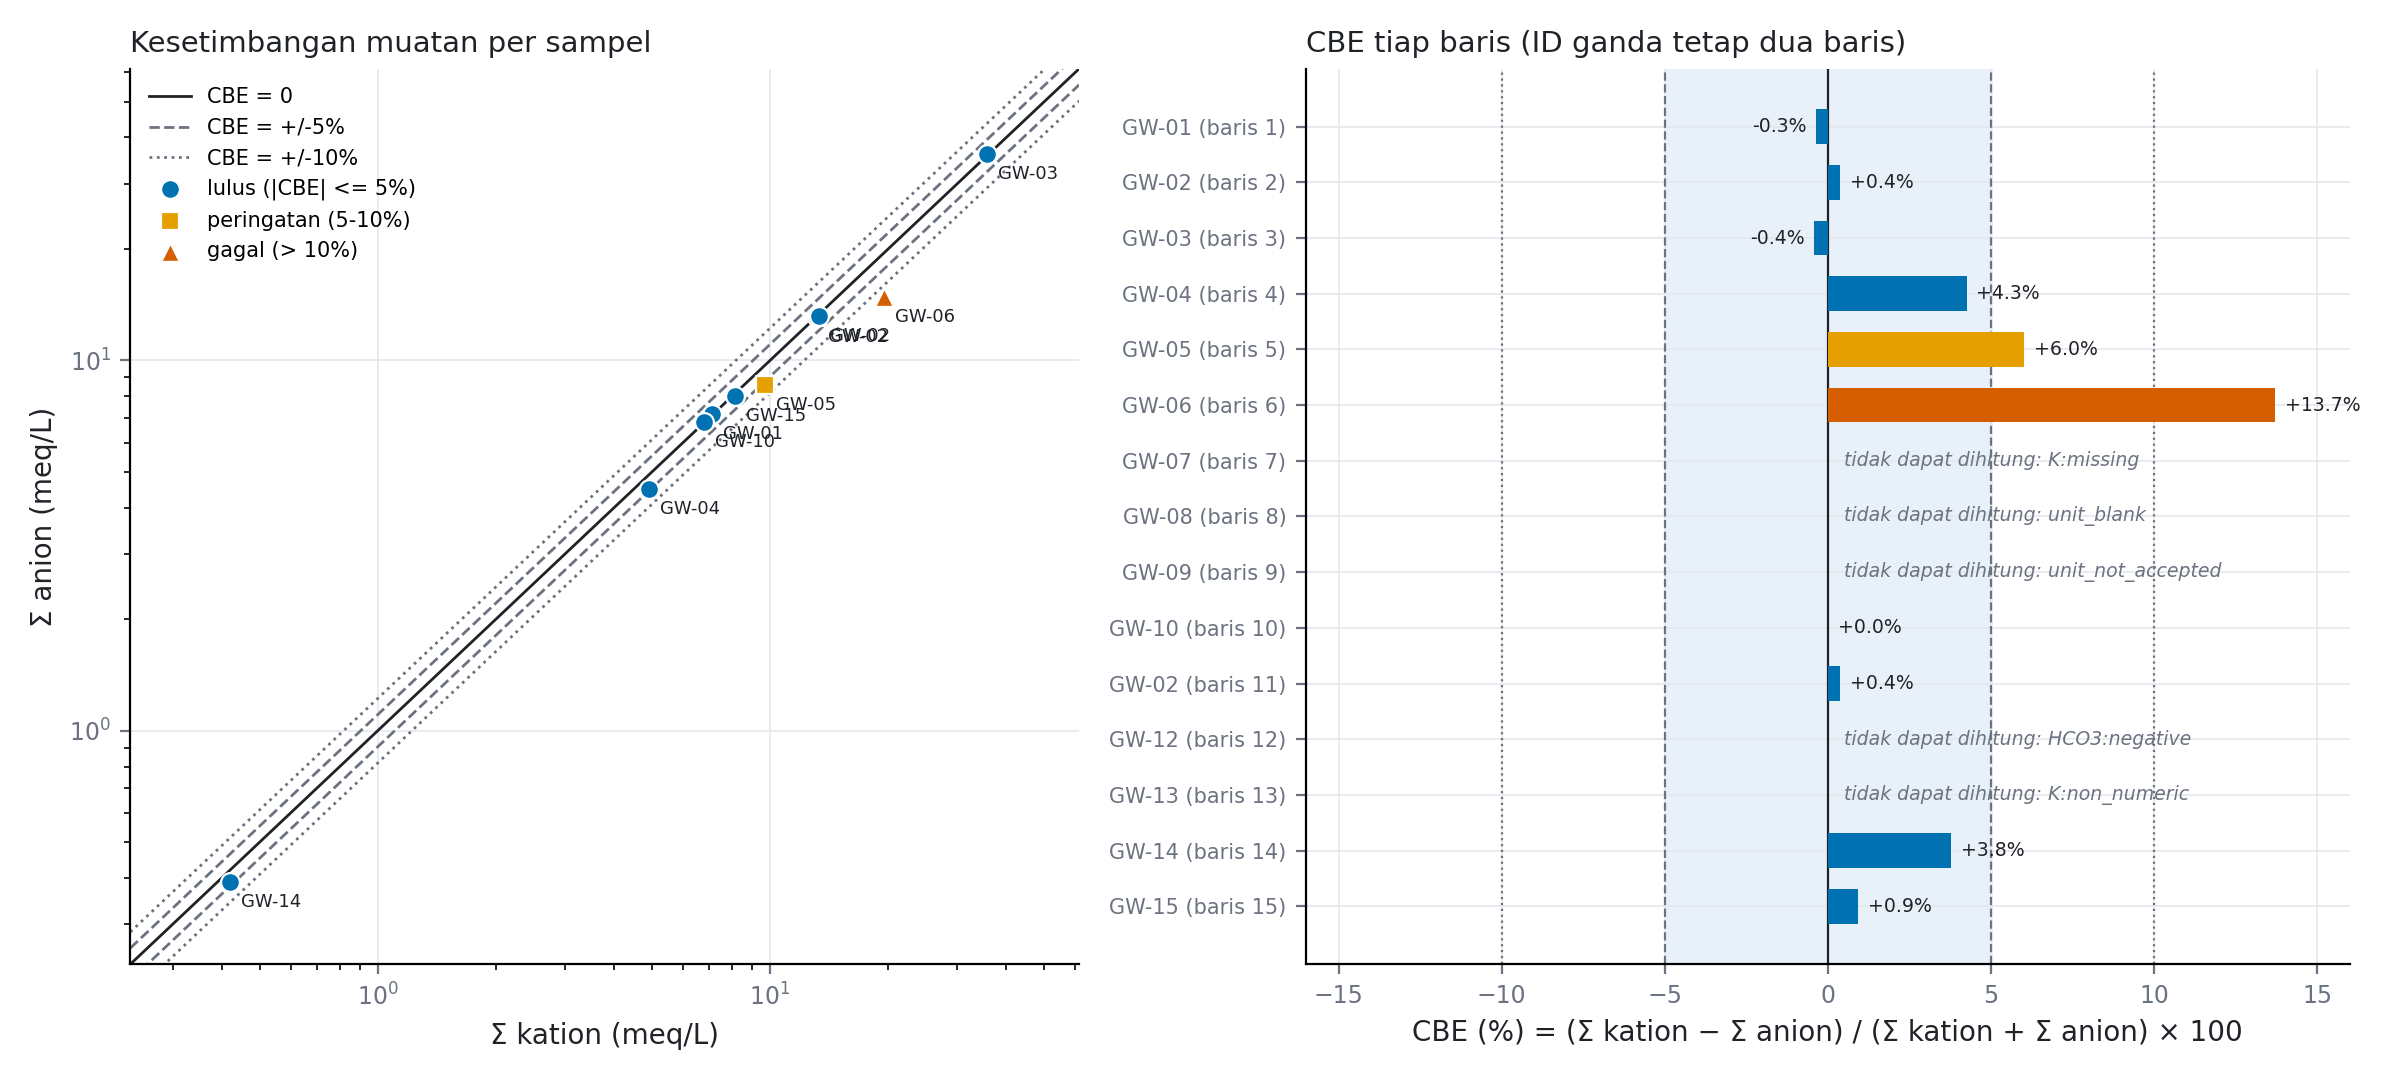

In [15]:
from IPython.display import Image
Image('figures/chemistry/r-chm-001_baseline.png')

### B.8.4 Interpretasi (observasi, perhitungan, inferensi, batasan dipisah)

* **Observasi.** Pada panel kiri, sampel `lulus` berada di antara garis ±5% sekitar garis 1:1, GW-05 (peringatan) berada di antara ±5% dan ±10%, dan GW-06 di luar garis ±10%. Pada panel kanan, lima baris ditandai `tidak dapat dihitung` dan **tidak** digambar sebagai batang nol. Baris ber-ID ganda (GW-02) tampil dua kali.
* **Perhitungan.** GW-06: Σ kation 19.500 meq/L terhadap Σ anion 14.800 meq/L → CBE +13.70%. GW-05: +6.01%. GW-04: +4.25%, yakni hanya 0.75 poin persen di bawah ambang 5%; uji sensitivitas HCO₃ ±2% **tidak** mengubah kelas sampel mana pun, dan satu-satunya sampel dalam 1 poin persen dari ambang (5% atau 10%) adalah GW-04 (baris 4). GW-14 berjumlah ion hanya 0.81 meq/L (kation + anion) dan CBE-nya +3.77%.
* **Inferensi (terbatas).** Pada data nyata, CBE positif besar seperti GW-06 biasanya mengarahkan peninjauan ke anion yang tidak dianalisis, kesalahan analitik, atau kesalahan entri data. Ini **hipotesis kerja untuk pemeriksaan laboratorium**, bukan kesimpulan; pada fixture sintetis ini penyebab angka tersebut adalah rancangan saya. Nilai GW-14 `lulus`, tetapi dengan total ion sekecil itu satu kesalahan analitik kecil sudah cukup menggeser kelasnya, sehingga status `lulus`-nya kurang kuat dibanding GW-01.
* **Batasan.**
  1. Kesesuaian dengan *expected-output* menguji bahwa **kode menjalankan kontrak pada kasus yang saya rancang**; bukan bukti bahwa data lapangan akan berperilaku sama.
  2. CBE kecil tidak membuktikan analisis benar (kesalahan saling meniadakan).
  3. Ambang 5% dan 10% adalah pilihan penyaringan; proyek lain dapat memakai ambang berbeda, dan itu cukup diubah di konfigurasi, bukan di kode.
  4. Perlakuan dua baris `GW-02` (analisis ulang atau salah label) **belum diputuskan**; keduanya dipertahankan dan di-flag untuk keputusan manusia.
  5. Tidak ada spesiasi, koreksi suhu, pH, atau ionic strength.

---

## B.9 Run gagal didokumentasikan (bukan dihapus)

Bab 2.4.3 melarang menghapus *failed run*. Tiga uji berikut dibuat agar terbukti bahwa guard dan check **benar-benar dapat gagal**.

### B.9.1 Guard kontrak: kolom `Fe` disyaratkan tetapi tidak ada di CSV (harapan: exit code 2, tanpa output ilmiah)

In [16]:
!python3 code/recipes/chemistry/r-chm-001.py --config configurations/r-chm-001-guard.json --stage audit; echo "exit code: $?"; ls results/chemistry/r-chm-001

[STOP] kolom yang disyaratkan kontrak tidak ada di CSV: ['Fe']
Failure record: results/run-records/r-chm-001-guard-trip-stop-audit.json
exit code: 2
baseline


Direktori run `guard-trip` **tidak dibuat**, hanya failure record `results/run-records/r-chm-001-guard-trip-stop-audit.json`. Tidak ada output yang bisa keliru dipromosikan.

### B.9.2 Penolakan menimpa: mengulang tahap audit untuk run `baseline` yang sudah ada (harapan: exit code 3)

In [17]:
!python3 code/recipes/chemistry/r-chm-001.py --config configurations/r-chm-001.json --stage audit; echo "exit code: $?"

[TOLAK-TIMPA] results/chemistry/r-chm-001/baseline sudah ada; gunakan run_name baru
exit code: 3


### B.9.3 Kontrol negatif: muatan Mg sengaja +1 (seharusnya +2)

Tiga tahap dijalankan penuh; hasilnya disimpan di `results/failed-runs/` dan **tidak boleh dipromosikan**.

In [18]:
!python3 code/recipes/chemistry/r-chm-001.py --config configurations/r-chm-001-negative.json --stage audit > /dev/null; echo "audit exit code: $?"; python3 code/recipes/chemistry/r-chm-001.py --config configurations/r-chm-001-negative.json --stage compute > /dev/null; echo "compute exit code: $?"; python3 code/recipes/chemistry/r-chm-001.py --config configurations/r-chm-001-negative.json --stage verify; echo "verify exit code: $?"

audit exit code: 0
compute exit code: 0
R-CHM-001 [negative-control] -> Executed as negative control (checks fail as expected)
  [PASS] input tidak berubah (SHA-256 sekarang = saat audit): True  (kriteria True)
  [PASS] jumlah baris terjaga (input = audit = balance): [15, 15, 15]  (kriteria ketiganya sama)
  [PASS] urutan sample_id terjaga (ID ganda tidak dibuang): True  (kriteria identik)
  [FAIL] jumlah per status = expected-output: {'lulus': 7, 'peringatan': 3, 'gagal': 0, 'tidak_dapat_dihitung': 5}  (kriteria {'lulus': 8, 'peringatan': 1, 'gagal': 1, 'tidak_dapat_dihitung': 5})
  [PASS] sampel tidak dapat dihitung = expected-output: ['GW-07', 'GW-08', 'GW-09', 'GW-12', 'GW-13']  (kriteria ['GW-07', 'GW-08', 'GW-09', 'GW-12', 'GW-13'])
  [PASS] keputusan 'dapat dihitung' sama dengan deteksi independen: True  (kriteria True)
  [PASS] sampel tidak dapat dihitung tidak diberi angka CBE (kosong, bukan 0/NaN): True  (kriteria True)
  [FAIL] CBE program vs hitung ulang independen: selisih

**Observasi:** dari 13 check, **4 gagal** (nomor 4, 8, 9, 10) dan **9 tetap lulus**. Check 4 gagal karena jumlah per status bergeser; check 8 gagal karena CBE program menyimpang dari hitung ulang independen (selisih maksimum 5,85 poin persen); check 9 dan 10 gagal karena muatan Mg salah terdeteksi oleh tabel dan hitungan tangan yang ditulis terpisah dari konfigurasi.

**Pelajaran desain:** check 11 dan 12 (invarian skala dan rumus analitik) **tetap lulus** pada kontrol negatif, sebab keduanya hanya menguji konsistensi internal kode terhadap konfigurasi yang sama, dan konfigurasi yang salah tetap konsisten dengan dirinya sendiri. Kesalahan pada konfigurasi hanya tertangkap oleh check yang **independen dari konfigurasi** (check 8, 9, 10). Inilah alasan tabel massa atom, rumus ion, dan muatan pada tahap `V` ditulis terpisah.

---

## B.10 Rerun di direktori bersih (determinisme)

Kode, konfigurasi, data, dan expected-output disalin ke direktori sementara yang kosong, ketiga tahap dijalankan ulang, lalu SHA-256 keluaran dibandingkan dengan run pertama. Run record dikecualikan dari perbandingan karena memuat `timestamp_utc`.

In [19]:
import hashlib, os, shutil, subprocess, sys, tempfile

tmp = tempfile.mkdtemp(prefix="r-chm-001-rerun-")
for d in ("code", "configurations", "data", "artifacts"):
    shutil.copytree(d, os.path.join(tmp, d))
for stage in ("audit", "compute", "verify"):
    r = subprocess.run([sys.executable, "code/recipes/chemistry/r-chm-001.py",
                        "--config", "configurations/r-chm-001.json", "--stage", stage],
                       cwd=tmp, capture_output=True, text=True)
    print(f"rerun {stage}: exit code {r.returncode}")

def sha(p):
    return hashlib.sha256(open(p, "rb").read()).hexdigest()

files = ["results/chemistry/r-chm-001/baseline/audit.csv",
         "results/chemistry/r-chm-001/baseline/audit.json",
         "results/chemistry/r-chm-001/baseline/balance.csv",
         "results/chemistry/r-chm-001/baseline/summary.json",
         "figures/chemistry/r-chm-001_baseline.png"]
for f in files:
    a, b = sha(f), sha(os.path.join(tmp, f))
    print(f"{'IDENTIK' if a == b else 'BERBEDA':8s} {a[:12]} {b[:12]}  {f}")
shutil.rmtree(tmp)

rerun audit: exit code 0
rerun compute: exit code 0
rerun verify: exit code 0
IDENTIK  54f8abd8d878 54f8abd8d878  results/chemistry/r-chm-001/baseline/audit.csv
IDENTIK  f20f78013285 f20f78013285  results/chemistry/r-chm-001/baseline/audit.json
IDENTIK  45a55dbdf13e 45a55dbdf13e  results/chemistry/r-chm-001/baseline/balance.csv
IDENTIK  082e43a51f51 082e43a51f51  results/chemistry/r-chm-001/baseline/summary.json
IDENTIK  01a2d522ed9c 01a2d522ed9c  figures/chemistry/r-chm-001_baseline.png


In [20]:
!cat results/run-records/r-chm-001-baseline.json

{
  "recipe_id": "R-CHM-001",
  "prompt_id": "P-CHM-001",
  "equation_id": "E-CHM-001",
  "run_name": "baseline",
  "run_kind": "baseline",
  "command": "python3 code/recipes/chemistry/r-chm-001.py --config configurations/r-chm-001.json --stage verify",
  "timestamp_utc": "2026-10-21T03:51:06+00:00",
  "environment": {
    "python": "3.12.3",
    "matplotlib": "3.10.8",
    "platform": "Linux-6.18.44-fc-v139-x86_64-with-glibc2.39"
  },
  "inputs": {
    "config": "configurations/r-chm-001.json",
    "config_sha256": "7cb6be9dc7eefca7cf9d99d48d69483003ca7a3fd2f99ede948a14e857b488cf",
    "data": "data/samples/groundwater-major-ions.csv",
    "data_sha256": "a4bbb93758530cfb6c54f727746afaac139d46bca3cf5208a8bbde2454fda7b6",
    "expected_outputs": "artifacts/expected-outputs/r-chm-001.json",
    "expected_outputs_sha256": "6d7c2ed766fa6976949f24061563d2d90c057dc004febbc82f8789e124b52ba4"
  },
  "code_sha256": "4b7f1c7d2f726b66e66b41e673ee54bbf617190282cd7fba0ecb85384d0711e6",
  "stages":

Keputusan: **seluruh 5 keluaran identik** pada rerun di direktori bersih. Skrip deterministik (tanpa bilangan acak).

---

## B.11 Status evidence dan identitas artifact

| Item | Nilai |
| :--- | :--- |
| Status | **Executed - all checks passed** |
| Exit code | `0` (tiga tahap: audit=0, compute=0, verify=0) |
| Waktu run verify (UTC, jam sistem sandbox) | `2026-10-21T03:51:06+00:00` |
| Lingkungan | Python 3.12.3, Matplotlib 3.10.8, Linux-6.18.44-fc-v139-x86_64-with-glibc2.39 |
| Run record | `results/run-records/r-chm-001-baseline.json` |
| Run gagal | `r-chm-001-guard-trip-stop-audit.json` (exit 2), `r-chm-001-negative-control.json` (check gagal seperti diharapkan), penolakan timpa (exit 3, tanpa record) |

| Artifact | SHA-256 (12 karakter awal) |
| :-- | :-- |
| `configurations/r-chm-001.json` | `7cb6be9dc7ee…` |
| `data/samples/groundwater-major-ions.csv` | `a4bbb9375853…` |
| `artifacts/expected-outputs/r-chm-001.json` | `6d7c2ed766fa…` |
| `code/recipes/chemistry/r-chm-001.py` | `4b7f1c7d2f72…` |
| `results/chemistry/r-chm-001/baseline/audit.csv` | `54f8abd8d878…` |
| `results/chemistry/r-chm-001/baseline/audit.json` | `f20f78013285…` |
| `results/chemistry/r-chm-001/baseline/balance.csv` | `45a55dbdf13e…` |
| `results/chemistry/r-chm-001/baseline/summary.json` | `082e43a51f51…` |
| `figures/chemistry/r-chm-001_baseline.png` | `01a2d522ed9c…` |

**Label yang tidak diklaim:** *validated against field data*, *calibrated*, *dapat dipakai untuk interpretasi fasies atau salinisasi*. Yang ditunjukkan hanyalah: kode menjalankan kontrak data dan rumus E-CHM-001 dengan benar pada fixture sintetis, dan check dapat gagal.

---

## B.12 Pemetaan ke tahapan pembuatan recipe (Bab 2.4.1)

| Tahap 2.4.1 | `R-IO-001` (Bagian A) | `R-CHM-001` (Bagian B) |
| :--- | :--- | :--- |
| 1. Problem dan batas keputusan | A.1 | B.1 (inferensi sumber dan salinisasi dipisah) |
| 2. Minimal theory dan asumsi | A.2 | B.2 (rumus, tanda muatan, 5 asumsi) |
| 3. Input dan constraint contract | A.3 | B.3 (desain fixture + 7 constraint) |
| 4. Prompt dan mekanisme terkecil | A.4 | B.4 (`P1 -> P2 -> V`; Python lokal saja) |
| 5. Implementasi sebagai artifact | A.5 | B.5 (config, expected output, kode terpisah) |
| 6. Output dan check sebelum run | A.3 (4 check) | B.6 (13 check, expected output ditulis sebelum run) |
| 7. Jalankan, catat status, revisi | A.6–A.7 | B.7–B.11 (run record, hash, failed run, rerun bersih) |

## B.13 Tindakan lanjutan (*Next Action*; usulan, **belum dikerjakan**)

1. **Keputusan manusia `[H]`** untuk dua baris `GW-02` dan lima sampel `tidak_dapat_dihitung` (koreksi di laboratorium atau tetap dikecualikan), sebelum recipe berikutnya memakai tabel ini.
2. **`R-CHM-002` (usulan):** tipe air dari proporsi ion (diagram Piper) hanya untuk sampel berstatus `lulus`.
3. **`R-CHM-003` (usulan):** rasio ion untuk penyaringan indikasi salinisasi, tanpa menyatakan sumber sebagai kesimpulan; memerlukan data nyata dengan provenance dan unit yang tercatat.